# From lens tolerances to wafer yield: a scanner lens budget

A lithography lens is specified on the wafer, not on the optical bench. What
the fab cares about is how much the CD of a line changes across the slit, how
far its best focus moves, and how far its image lands from where it should
(overlay). Each of these is set by milliwaves of aberration, and each
milliwave comes from some radius, thickness, centring or glass error of one
of the twenty-odd elements. This notebook joins the two ends with the tools
of earlier notebooks:

- notebook 70 (Monte Carlo tolerancing) built the tolerance machinery
  (`pyoptics.tolerancing`): tolerances, compensators, Monte Carlo runs and the
  linear model, on an achromat and on Caldwell's KrF lens with a wavefront
  merit,
- notebook 33 (lens aberrations across the slit) turned a ray traced lens into
  Zernikes, placement and best focus across the scanner slit and computed the
  Zernike sensitivities of CD, placement and best focus (`pyoptics.litho.lens`).

New here are the tolerances that a precision lens is really limited by
(element **tilt**, **wedge**, surface **irregularity** in fringes of
astigmatism and spherical aberration, and index **inhomogeneity** of the
blank), the chain to the wafer (`pyoptics.litho.budget`), the scanner's
**compensators** (wafer focus and levelling, the laser wavelength and lens
manipulators that move elements along and across the axis or tilt them, with
limited strokes), and the reverse question: **which tolerances** a given
budget allows (inverse sensitivity and allocation).

The chain, for every lens drawn from the tolerances:

1. trace the perturbed lens at the slit positions and fit Fringe Zernikes and
   the placement of a small feature (`SlitAberrations`), with the scanner's
   correction of translation, magnification and rotation,
2. multiply the Zernike changes with the sensitivities of each feature at each
   slit position (`slit_sensitivities()`), which gives CD, placement and best
   focus changes (`LithoErrors`, `wafer_errors()`),
3. let the compensators minimize these changes, as the scanner does at
   set-up,
4. count the lenses that meet the specification (`wafer_yield()`).

Sections:

1. The new tolerances: what a tilt, a wedge, an irregularity and an
   inhomogeneity do across the slit
2. Three features and their Zernike sensitivities across the slit
3. A precision tolerance set, the sensitivity table and the linear model
   against full traces
4. The wafer budget: CD uniformity, overlay and best focus
5. Compensators: wafer focus and tilt, wavelength, lens manipulators
6. Inverse sensitivity and tolerance allocation, and the manipulator strokes

Run time: about 8 minutes, most of it the Jacobian (two traces per tolerance)
and the fully traced Monte Carlo lenses.

The lens is Caldwell's all fused silica KrF design (`caldwell_krf_lens()`:
248.3 nm, NA 0.56, 4x reduction, image field Ø 23.4 mm, telecentric on both
sides; notebook 44, Seidel aberrations, analysed its design). The slit is
22 × 5 mm on the wafer. To keep the run time down the aberrations are taken
at seven slit positions $x$ on the scan centre line $y = 0$ (the static image;
notebook 33, lens aberrations across the slit, averages over the scan with
`y=...`). The performance vector holds, per slit position, the changes of
Fringe Zernikes $Z_4$ to $Z_{25}$ and of the placement against the nominal
lens: 24 numbers, 168 in all.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import lens_optimization as lo
from pyoptics import tolerancing as tol
from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, budget, lens
from pyoptics.raytrace import caldwell_krf_lens

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.grid": True, "grid.color": "0.88", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False})
t_start = time.time()
BLUE, ORANGE, GREEN, YELLOW, RED, PURPLE, GREY = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#d03b3b",
                                                  "#8a5cc2", "#888888")
GROUP_COLOR = {"radius": BLUE, "thickness": GREEN, "index": RED, "decenter": ORANGE, "tilt": YELLOW,
               "wedge": PURPLE, "irregularity": "#4a4a4a", "inhomogeneity": "#c27ba0"}

system = caldwell_krf_lens()          # mm, KrF 248.3 nm, NA 0.56, 4x
X_SLIT = np.linspace(-11.0, 11.0, 7)  # slit positions on the wafer [mm], the slit is 22 x 5 mm
ab = budget.SlitAberrations(system, X_SLIT, y=(0.0,), terms=range(4, 26), N=16)
print(f"NA {ab.NA:.4f}, wavelength {ab.wavelength:.1f} nm, {len(X_SLIT)} slit positions, "
      f"vector of {len(ab(system))} numbers")

NA 0.5581, wavelength 248.3 nm, 7 slit positions, vector of 168 numbers


## 1. The new tolerances

`pyoptics.tolerancing` gains four kinds of tolerance:

- `Tilt(first, last, angle, axis, pivot)`: the element turns as a rigid body
  about a point on the axis (default: midway between its vertices). Every
  surface is tilted, and its vertex moves on the circle about the pivot,
  sideways and along the axis.
- `Wedge(surface, angle, axis)`: one surface tilted about its own vertex.
  A wedge of $\alpha$ is an edge thickness difference of about $\alpha D$ on
  an element of diameter $D$ (10 µrad on a 200 mm lens: 2 µm).
- `Irregularity(surface, fringes, rim, term)`: a figure error with the shape
  of one Fringe Zernike, peak-to-valley $N\lambda_\mathrm{test}/2$ over the
  rim. The surface becomes a `ZernikeSurface`. The usual specification "N
  fringes of irregularity" is modelled as astigmatism ($Z_5$, $Z_6$) and
  spherical aberration ($Z_9$).
- `Inhomogeneity(first, last, dn, rim, term)`: the index of the blank varies
  by $\Delta n\, f(x, y)$ with $f$ a Zernike shape of unit peak-to-valley
  ($Z_2$, $Z_3$: a gradient, $Z_4$: radial, $Z_5$, $Z_6$: from stress). For a
  thin element this is an extra optical path $t\,\Delta n\, f$, put on the
  first surface as an equivalent departure of the sag.

`element_tolerances()` takes them as `tilt=`, `wedge=`, `irregularity=` and
`inhomogeneity=`. The figure shows what single errors do across the slit (no
compensators; the grey squares are the placement after the scanner's linear
correction, right axis).

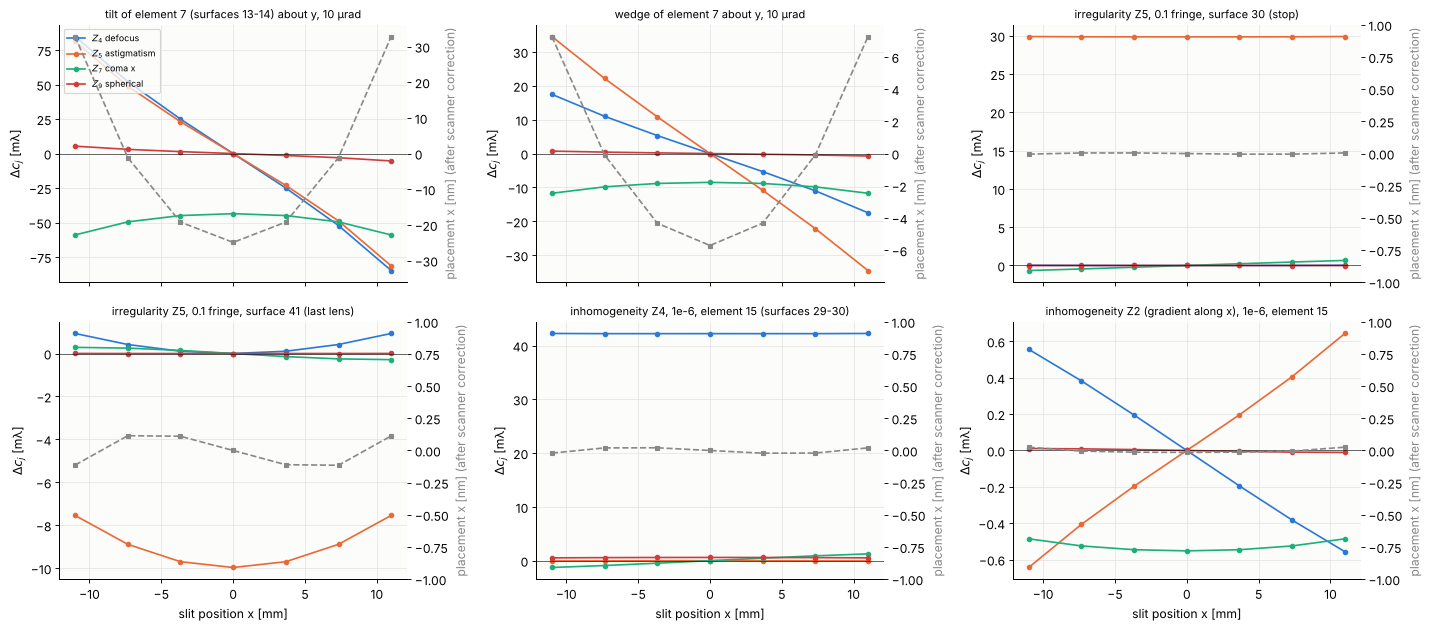

In [2]:
examples = [("tilt of element 7 (surfaces 13-14) about y, 10 µrad", tol.Tilt(12, 13, 1e-5, "y"), 1e-5),
            ("wedge of element 7 about y, 10 µrad", tol.Wedge(13, 1e-5, "y"), 1e-5),
            ("irregularity Z5, 0.1 fringe, surface 30 (stop)",
             tol.Irregularity(29, 0.1, system.surfaces[29].semi_diameter, 5), 0.1),
            ("irregularity Z5, 0.1 fringe, surface 41 (last lens)",
             tol.Irregularity(40, 0.1, system.surfaces[40].semi_diameter, 5), 0.1),
            ("inhomogeneity Z4, 1e-6, element 15 (surfaces 29-30)",
             tol.Inhomogeneity(28, 29, 1e-6, system.surfaces[28].semi_diameter, 4), 1e-6),
            ("inhomogeneity Z2 (gradient along x), 1e-6, element 15",
             tol.Inhomogeneity(28, 29, 1e-6, system.surfaces[28].semi_diameter, 2), 1e-6)]
SHOW = {4: ("$Z_4$ defocus", BLUE), 5: ("$Z_5$ astigmatism", ORANGE), 7: ("$Z_7$ coma x", GREEN),
        9: ("$Z_9$ spherical", RED)}
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
for ax, (title, t, v) in zip(axes.ravel(), examples):
    s = system.copy()
    t.apply(s, v)
    dZ, dP = ab.unpack(ab(s))
    for j, (lab, c) in SHOW.items():
        ax.plot(X_SLIT, 1000*dZ[0, :, list(ab.terms).index(j)], "o-", color=c, ms=4, label=lab)
    ax2 = ax.twinx()
    ax2.plot(X_SLIT, dP[0, :, 0], "s--", color=GREY, ms=4, label="placement x")
    lim = max(1.0, 1.1*np.max(np.abs(dP[0, :, 0])))
    ax2.set_ylim(-lim, lim)
    ax2.set_ylabel("placement x [nm] (after scanner correction)", color=GREY)
    ax2.grid(False)
    ax.set_title(title, fontsize=10)
    ax.set_ylabel("$\\Delta c_j$ [mλ]")
    ax.axhline(0, color="k", lw=0.5)
for ax in axes[1]:
    ax.set_xlabel("slit position x [mm]")
axes[0, 0].legend(fontsize=8, loc="upper left")
fig.tight_layout()

Where an error sits in the lens decides how it shows across the field:

- The **tilt** of element 7 adds defocus and astigmatism that grow linearly
  with $x$, a tilted image surface and a linear astigmatism (the field
  dependence that nodal aberration theory predicts for a tilted element),
  plus some coma. The placement error is a curved distortion of up to 30 nm,
  which the scanner's linear correction cannot remove. The **wedge** of the
  same element does the same at less than half the strength.
- An **irregularity** of 0.1 fringe of $Z_5$ on the stop surface gives 30 mλ
  of astigmatism, the same everywhere in the field: all field points use the
  whole surface. The same error on the last lens, close to the wafer, gives
  only 8 to 10 mλ, and it varies over the field: each field point sees a small
  patch of the surface, and the patches of different field points differ. A
  pupil surface turns figure errors into constant aberrations, a field
  surface into field-dependent ones (and into distortion).
- An **inhomogeneity** of $10^{-6}$ with a radial profile across a 22 mm thick
  element at the stop is 42 mλ of pure defocus, the same everywhere, which the
  wafer focus takes out. The same $\Delta n$ as a gradient across the element
  tilts the wavefront, a uniform image shift that the scanner corrects, and
  leaves only a little field-dependent defocus and astigmatism.

## 2. Three features and their sensitivities across the slit

Three patterns at KrF, binary mask, conventional illumination $\sigma = 0.6$,
threshold 0.3, dose to size on the ideal lens:

- dense vertical lines, 250 nm lines and spaces ($k_1 = 0.56$), cut along
  $x$,
- the same lines horizontal (cut along $y$, placement along $y$),
- isolated vertical lines, 250 nm at a pitch of 1500 nm.

`slit_sensitivities()` computes the derivatives of CD, placement and best
focus with respect to $Z_4 \ldots Z_{25}$ at each slit position. Unlike in
notebook 33 (lens aberrations across the slit), they are taken **about the
lens's own aberrations there** (the nominal Zernikes at that slit position),
because a perturbation adds to them: the nominal lens has about 100 mλ of
defocus, astigmatism and coma at the slit edge, and these change the
sensitivities. Bars: slit centre; diamonds: slit edge.

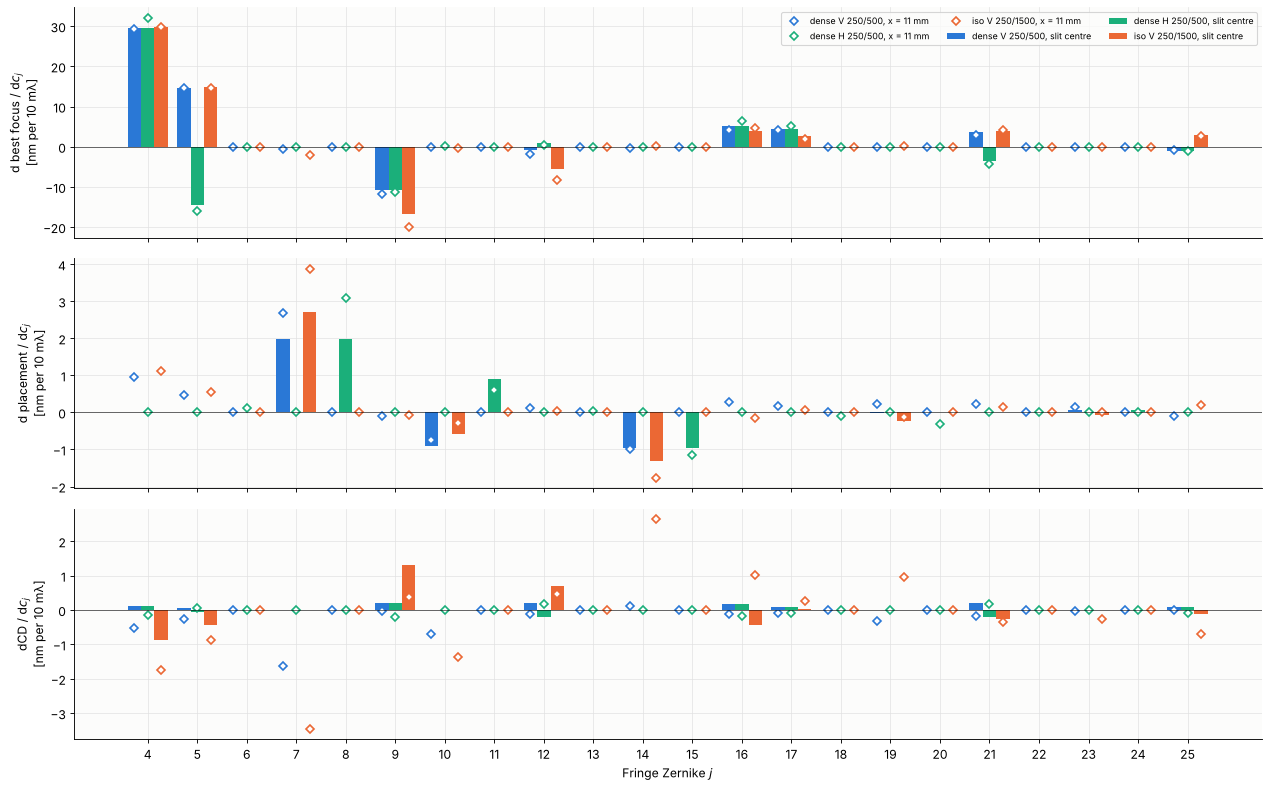

In [3]:
ill = Illumination.conventional(0.6, n_samples=21)
ideal = Projector(ab.NA, ab.wavelength, magnification=4.0)
patterns = {"dense V 250/500": MaskLayout.lines_spaces(500.0, 250.0),
            "dense H 250/500": MaskLayout.lines_spaces(500.0, 250.0, orientation="x"),
            "iso V 250/1500": MaskLayout.lines_spaces(1500.0, 250.0)}
features = []
for name, layout in patterns.items():
    sim = LithoSimulation(layout, ThinMask.binary(), ill, ideal)
    features.append(budget.slit_sensitivities(sim, ab, name, dose=sim.dose_to_size(threshold=0.3)))
FEAT_COLOR = {"dense V 250/500": BLUE, "dense H 250/500": GREEN, "iso V 250/1500": ORANGE}

terms = ab.terms
fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True)
for ax, key, yl in zip(axes, ("best_focus", "placement", "cd"),
                       ("d best focus / d$c_j$\n[nm per 10 mλ]", "d placement / d$c_j$\n[nm per 10 mλ]",
                        "dCD / d$c_j$\n[nm per 10 mλ]")):
    for k, f in enumerate(features):
        ax.bar(terms + (k - 1)*0.27, 0.01*f.sensitivities[3].linear[key], 0.27, color=FEAT_COLOR[f.name],
               label=f"{f.name}, slit centre" if key == "best_focus" else None)
        ax.plot(terms + (k - 1)*0.27, 0.01*f.sensitivities[-1].linear[key], "D", ms=5, mfc="white",
                mec=FEAT_COLOR[f.name], mew=1.5,
                label=f"{f.name}, x = {X_SLIT[-1]:.0f} mm" if key == "best_focus" else None)
    ax.set_ylabel(yl)
    ax.axhline(0, color="k", lw=0.5)
axes[0].legend(fontsize=8, ncol=3)
axes[-1].set_xticks(terms)
axes[-1].set_xlabel("Fringe Zernike $j$")
fig.tight_layout()

At the slit centre the pattern follows from symmetry (notebook 33, lens aberrations across the slit):
best focus responds to the even terms ($Z_4$,
$Z_5$ with opposite signs for vertical and horizontal lines, $Z_9$,
$Z_{12}$, $Z_{16}$), placement to the odd ones ($Z_7$, $Z_{10}$, $Z_{14}$
for a cut along $x$; $Z_8$, $Z_{11}$, $Z_{15}$ along $y$), and CD has
almost no linear sensitivity. At the slit edge the nominal coma and defocus
of the lens mix the classes: placement now responds to defocus and
astigmatism (coma times defocus shifts the image), and CD responds linearly to
coma and trefoil, up to 3 nm per 10 mλ of $Z_7$ for the isolated lines. A
sensitivity table taken on the ideal lens would miss these terms entirely.

## 3. A precision tolerance set and the linear model

The lithographic error vector `LithoErrors` holds, per slit position and
feature, the linear changes of CD, placement and best focus divided by their
specifications (here the lens's share: 5 nm CD, 10 nm placement, 50 nm best
focus), followed by the Zernike changes themselves. Those are weighted with
the quadratic CD sensitivities, $w_j^2 = w_0^2 + \max|Q_j|/(2\,\mathrm{CD}_\mathrm{spec})$,
so that a term counts one unit where its quadratic CD change reaches the
specification. The merit, the RMS of the block norms, is then in
specification units: below 1 is good.

The tolerances are a demanding precision optics set, for all 21 elements:

| kind | limit |
|---|---|
| power | 0.5 fringe (HeNe, on the clear aperture) |
| irregularity | 0.05 fringe each of $Z_5$, $Z_6$, $Z_9$ |
| centre thickness, air spaces | ±2 µm |
| index (melt) | ±1·10⁻⁶ |
| inhomogeneity | 5·10⁻⁷ each of $Z_2$, $Z_3$, $Z_4$ |
| decentre of each element | ±1 µm in $x$ and $y$ |
| tilt and wedge of each element | ±5 µrad about $x$ and $y$ |

All are Gaussian, cut at the limit (sigma = limit/2). The wafer focus is
adjusted for every lens. The linear model needs two traces per tolerance.

In [4]:
SPEC = dict(cd=5.0, placement=10.0, focus=50.0)  # nm: lens share of the budget
errors = budget.LithoErrors(ab, features, **SPEC)
tols = tol.element_tolerances(system, fringes=0.5, irregularity=0.05, thickness=0.002, air=0.002,
                              index=1e-6, inhomogeneity=5e-7, decenter=0.001, tilt=5e-6, wedge=5e-6)
groups = sorted(set(t.group for t in tols), key=list(GROUP_COLOR).index)
print(f"{len(tols)} tolerances:", {g: sum(t.group == g for t in tols) for g in groups})
WAFER = [lo.Thickness(-1), tol.ImageTilt("y")]   # wafer focus and tilt about y (along the slit)
t0 = time.time()
analysis = tol.ToleranceAnalysis(system, tols, errors, compensators=WAFER[:1])
model = analysis.linear_model()
print(f"Jacobian: {2*len(tols)} lens traces in {time.time() - t0:.0f} s")

419 tolerances: {'radius': 42, 'thickness': 41, 'index': 21, 'decenter': 42, 'tilt': 42, 'wedge': 42, 'irregularity': 126, 'inhomogeneity': 63}


Jacobian: 838 lens traces in 221 s


### The sensitivity table and the full traces

The share of each tolerance in the mean square merit (with the wafer focus
adjusted), and 40 random lenses traced completely (every perturbation
applied, the focus compensated by Gauss-Newton with the nominal Jacobian) against
the linear model. The names give the surfaces, counted from 1: `ty11-12` is the
tilt about $y$ of the element with the surfaces 11 and 12 (element 6),
`wy12` the wedge of surface 12, `dx27-28` a decentre along $x$, `t12` the
thickness behind surface 12.

RSS merit (focus only): 8.90 specification units


40 lenses traced and compensated in 148 s
dense V 250/500: largest difference full - linear: CD 0.02 nm, placement 0.02 nm, best focus 0.12 nm
dense H 250/500: largest difference full - linear: CD 0.00 nm, placement 0.01 nm, best focus 0.05 nm
iso V 250/1500: largest difference full - linear: CD 0.05 nm, placement 0.03 nm, best focus 0.15 nm


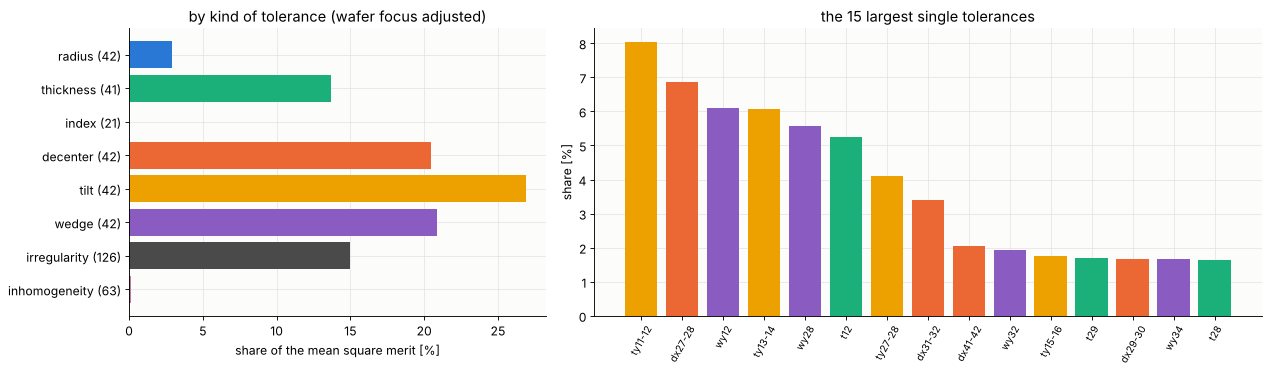

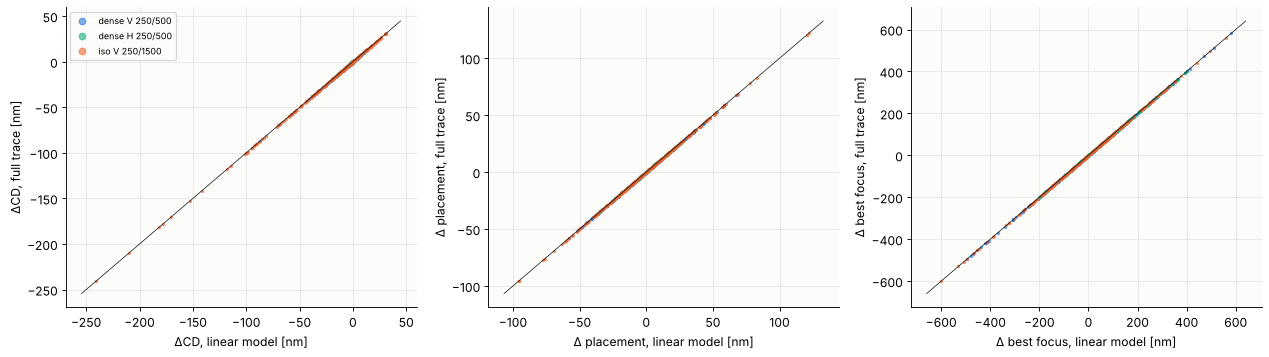

In [5]:
sig = np.array([t.sigma for t in tols])
contrib = sig**2*np.sum(model.B**2, axis=0)/len(analysis.blocks)   # mean square per tolerance
print(f"RSS merit (focus only): {np.sqrt(model.mean_square()):.2f} specification units")
by_group = {g: contrib[[t.group == g for t in tols]].sum() for g in groups}
top = np.argsort(contrib)[::-1][:15]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
ax.barh(range(len(groups)), [by_group[g]/contrib.sum()*100 for g in groups],
        color=[GROUP_COLOR[g] for g in groups])
ax.set_yticks(range(len(groups)), [f"{g} ({sum(t.group == g for t in tols)})" for g in groups])
ax.invert_yaxis()
ax.set_xlabel("share of the mean square merit [%]")
ax.set_title("by kind of tolerance (wafer focus adjusted)")
ax = axes[1]
ax.bar(range(len(top)), contrib[top]/contrib.sum()*100, color=[GROUP_COLOR[tols[k].group] for k in top])
ax.set_xticks(range(len(top)), [tols[k].name for k in top], rotation=60, fontsize=9)
ax.set_ylabel("share [%]")
ax.set_title("the 15 largest single tolerances")
fig.tight_layout()

N_FULL = 40
t0 = time.time()
X_full = analysis.sample(N_FULL, seed=11)
full = analysis.monte_carlo(values=X_full, vectors=True)
lin = model.predict(X_full, vectors=True)
print(f"{N_FULL} lenses traced and compensated in {time.time() - t0:.0f} s")
w_full, w_lin = budget.wafer_errors(errors, full.vectors), budget.wafer_errors(errors, lin.vectors)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, key, lab in zip(axes, ("cd", "placement", "best_focus"), ("ΔCD", "Δ placement", "Δ best focus")):
    for name, wf in w_full.items():
        a, b = getattr(wf, key).ravel(), getattr(w_lin[name], key).ravel()
        ax.plot(b, a, ".", color=FEAT_COLOR[name], ms=4, alpha=0.6, label=name)
    lim = ax.get_xlim()
    ax.plot(lim, lim, "k-", lw=0.6)
    ax.set_xlabel(f"{lab}, linear model [nm]")
    ax.set_ylabel(f"{lab}, full trace [nm]")
axes[0].legend(fontsize=8, markerscale=3)
fig.tight_layout()
for name in w_full:
    d = [np.max(np.abs(getattr(w_full[name], k) - getattr(w_lin[name], k))) for k in ("cd", "placement", "best_focus")]
    print(f"{name}: largest difference full - linear: CD {d[0]:.2f} nm, placement {d[1]:.2f} nm, "
          f"best focus {d[2]:.2f} nm")

The lens is limited by its **geometry**, not by its glass: tilts, wedges and
decentres together take about 70 % of the merit, led by the tilts of elements
6 and 7 and the decentre of element 14, followed by the thicknesses and the
irregularities. Index and inhomogeneity hardly count at this level: a
fused silica lens of one material shares any index change among all
elements, and a uniform index change is mostly a focus shift. The linear model
agrees with the full traces to a fraction of a nanometre: at these tolerance
levels the lens is linear, and everything below uses the linear model, which
evaluates 20 000 lenses in seconds.

## 4. The wafer budget

20 000 lenses from the linear model, with their performance vectors
(`monte_carlo(..., vectors=True)`), through the quadratic sensitivities
(`wafer_errors()`).

wafer focus adjusted:
  dense V 250/500   CD 3σ  30.9 nm   placement 3σ  58.5 nm   best focus 3σ   486 nm, range across the slit   406 nm
  dense H 250/500   CD 3σ  13.8 nm   placement 3σ  42.4 nm   best focus 3σ   326 nm, range across the slit   195 nm
  iso V 250/1500    CD 3σ 100.0 nm   placement 3σ  81.1 nm   best focus 3σ   494 nm, range across the slit   408 nm
  yield (|ΔCD| ≤ 5 nm, |Δ placement| ≤ 10 nm, |Δ best focus| ≤ 50 nm everywhere): 0.0 %


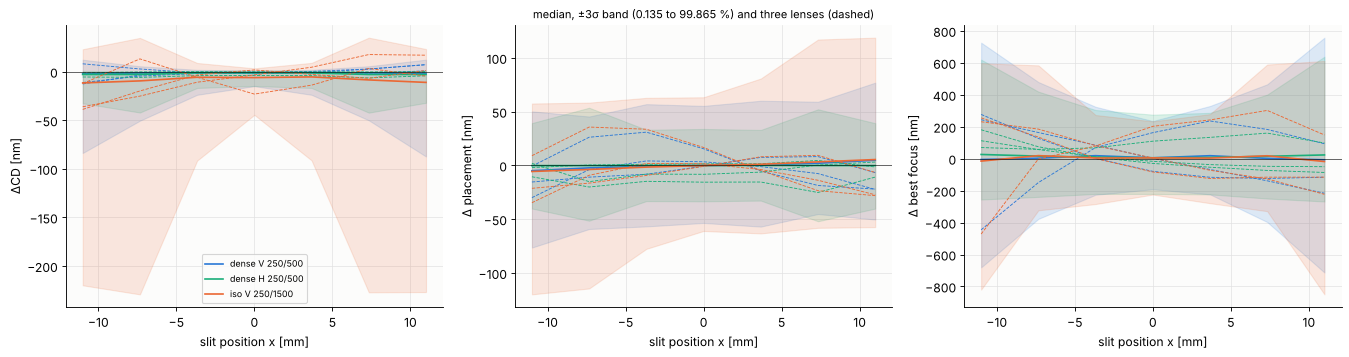

In [6]:
N_MC = 20000
mc = model.monte_carlo(N_MC, seed=1, vectors=True)
wafer = budget.wafer_errors(errors, mc.vectors)


def show_summary(wafer, label):
    S = budget.wafer_summary(wafer)
    print(f"{label}:")
    for name, v in S.items():
        print(f"  {name:16s}  CD 3σ {v['cd_3sigma']:5.1f} nm   placement 3σ {v['placement_3sigma']:5.1f} nm   "
              f"best focus 3σ {v['focus_3sigma']:5.0f} nm, range across the slit {v['focus_range']:5.0f} nm")
    y = budget.wafer_yield(wafer, SPEC["cd"], SPEC["placement"], SPEC["focus"])
    print(f"  yield (|ΔCD| ≤ {SPEC['cd']:.0f} nm, |Δ placement| ≤ {SPEC['placement']:.0f} nm, "
          f"|Δ best focus| ≤ {SPEC['focus']:.0f} nm everywhere): {100*y:.1f} %")
    return y


show_summary(wafer, "wafer focus adjusted")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, key, lab in zip(axes, ("cd", "placement", "best_focus"), ("ΔCD", "Δ placement", "Δ best focus")):
    for name, w in wafer.items():
        v = getattr(w, key)
        lo_, med, hi = np.percentile(v, [0.135, 50, 99.865], axis=0)
        ax.fill_between(X_SLIT, lo_, hi, color=FEAT_COLOR[name], alpha=0.15)
        ax.plot(X_SLIT, med, "-", color=FEAT_COLOR[name], label=name)
        ax.plot(X_SLIT, v[:3].T, "--", color=FEAT_COLOR[name], lw=0.8)
    ax.set_xlabel("slit position x [mm]")
    ax.set_ylabel(f"{lab} [nm]")
    ax.axhline(0, color="k", lw=0.5)
axes[0].legend(fontsize=8)
axes[1].set_title("median, ±3σ band (0.135 to 99.865 %) and three lenses (dashed)", fontsize=10)
fig.tight_layout()

With only the wafer focus adjusted, the lens is far out of
specification: the best focus varies by several hundred nanometres across the
slit (a tilted and curved image surface), placements by tens of nanometres,
and the CD of the isolated lines by up to 100 nm (3σ) at the slit edges, where
the nominal aberrations make CD respond linearly to the defocus that the
errors add. None of the 20 000 lenses meets the specification everywhere.
This is the normal state of a freshly assembled scanner lens. It is not
delivered like that.

## 5. Compensators

A scanner adjusts at set-up, and then continuously:

- the **wafer focus** and the **wafer tilt** about $y$ (levelling, which
  removes a focus slope along the slit; the tilt about $x$ is averaged by the
  scan),
- the **laser wavelength**: with one glass the lens has a large axial
  colour (about 0.25 µm per pm), so a wavelength shift moves focus and changes
  spherical aberration across the field,
- **lens manipulators**: elements mounted on actuators that move them along
  the axis (`AirSpace`), across it (`LateralShift`) or tilt them
  (`ElementTilt`).

Manipulators have limited strokes. The compensation therefore minimizes
$|y|^2 + \sum_c (\Delta c/r_c)^2$ with soft ranges $r_c$ (`ranges=` of
`ToleranceAnalysis`): 50 µm along the axis, 20 µm across, 50 µrad of tilt,
2 pm of wavelength. Which elements to put on actuators is chosen greedily
from all 107 candidates with the linear model: each step adds the
manipulator that lowers the merit most (`with_compensators()` with the
Jacobians of all candidates, traced once).

In [7]:
cands = ([lo.AirSpace(a, b) for a, b in system.elements()[1:]]
         + [tol.LateralShift(a, b, axis, typical=0.01) for a, b in system.elements() for axis in "xy"]
         + [tol.ElementTilt(a, b, axis) for a, b in system.elements() for axis in "xy"])
base = WAFER + [tol.Wavelength()]
# soft ranges (strokes) in mm and rad; None: free
RANGE = {lo.AirSpace: 0.05, tol.LateralShift: 0.02, tol.ElementTilt: 5e-5, tol.Wavelength: 2e-9}


def ranges(comps):
    return [RANGE.get(type(c)) for c in comps]


ELEMENT = {a: k + 1 for k, (a, b) in enumerate(system.elements())}   # first surface -> element number


def mlabel(c):
    """Short name of a compensator, with elements numbered from the object side."""
    if isinstance(c, lo.AirSpace):
        return f"z E{ELEMENT[c.first]}"
    if isinstance(c, tol.LateralShift):
        return f"{'xy'[c.k]} E{ELEMENT[c.first]}"
    if isinstance(c, tol.ElementTilt):
        return f"tilt {c.axis} E{ELEMENT[c.first]}"
    return {"t-1": "wafer focus", "image tilt y": "wafer tilt y"}.get(c.name, c.name)


t0 = time.time()
C_w, G_w = analysis.compensator_jacobian(base)
C_c, G_c = analysis.compensator_jacobian(cands)
print(f"Jacobians of {len(cands) + 3} manipulators in {time.time() - t0:.0f} s")
stages = {"wafer focus": model.with_compensators(WAFER[:1], C_w[:, :1], G_w[:, :1]),
          "+ wafer tilt": model.with_compensators(WAFER, C_w[:, :2], G_w[:, :2]),
          "+ wavelength": model.with_compensators(base, C_w, G_w, ranges=ranges(base))}
chosen, curve = [], [stages["+ wavelength"].mean_square()]
N_MAN = 10
for step in range(N_MAN):
    best = None
    for i in range(len(cands)):
        if i in chosen:
            continue
        idx = chosen + [i]
        comps = base + [cands[k] for k in idx]
        m = model.with_compensators(comps, np.hstack([C_w, C_c[:, idx]]), np.hstack([G_w, G_c[:, idx]]),
                                    ranges=ranges(comps))
        ms = m.mean_square()
        if best is None or ms < best[0]:
            best = (ms, i, m)
    chosen.append(best[1])
    curve.append(best[0])
    if step in (3, N_MAN - 1):
        stages[f"+ {step + 1} lens manipulators"] = best[2]
print("manipulators in the order chosen:", ", ".join(mlabel(cands[i]) for i in chosen))

Jacobians of 107 manipulators in 141 s


manipulators in the order chosen: x E4, z E10, tilt y E13, z E6, y E16, x E3, z E17, z E13, tilt x E13, z E7


wafer focus                  yield   0.0 %
+ wafer tilt                 yield   0.0 %
+ wavelength                 yield   0.0 %
+ 4 lens manipulators        yield   3.3 %
+ 10 lens manipulators       yield  62.9 %


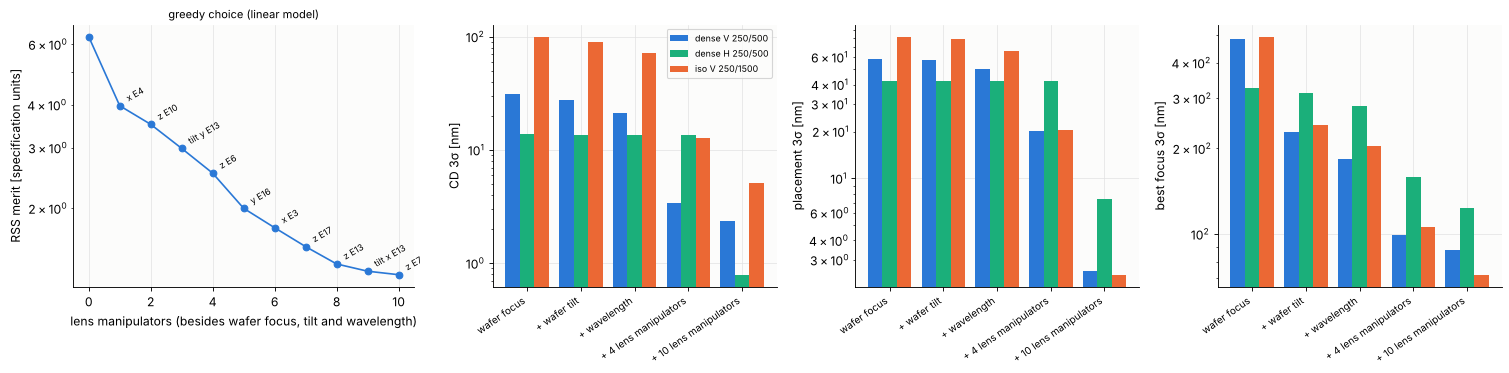

In [8]:
results = {}
for label, m in stages.items():
    w = budget.wafer_errors(errors, m.monte_carlo(N_MC, seed=1, vectors=True).vectors)
    results[label] = (budget.wafer_summary(w), budget.wafer_yield(w, SPEC["cd"], SPEC["placement"], SPEC["focus"]))
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), gridspec_kw={"width_ratios": [1.2, 1, 1, 1]})
ax = axes[0]
ax.semilogy(range(len(curve)), np.sqrt(curve), "o-", color=BLUE)
for k, i in enumerate(chosen):
    ax.annotate(mlabel(cands[i]), (k + 1, np.sqrt(curve[k + 1])), textcoords="offset points", xytext=(4, 4),
                fontsize=8, rotation=30)
ax.set_xlabel("lens manipulators (besides wafer focus, tilt and wavelength)")
ax.set_ylabel("RSS merit [specification units]")
ax.set_title("greedy choice (linear model)", fontsize=10)
labels = list(results)
for ax, key, lab in zip(axes[1:], ("cd_3sigma", "placement_3sigma", "focus_3sigma"),
                        ("CD 3σ [nm]", "placement 3σ [nm]", "best focus 3σ [nm]")):
    for k, f in enumerate(features):
        ax.bar(np.arange(len(labels)) + (k - 1)*0.27, [results[l][0][f.name][key] for l in labels], 0.27,
               color=FEAT_COLOR[f.name], label=f.name)
    ax.set_yscale("log")
    ax.set_xticks(range(len(labels)), labels, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel(lab)
axes[1].legend(fontsize=8)
fig.tight_layout()
for label in labels:
    print(f"{label:28s} yield {100*results[label][1]:5.1f} %")

Each step of compensation helps where it can:

- **wafer tilt** halves the best focus spread of the vertical lines; the
  horizontal lines gain less because their best focus moves with astigmatism,
  which a tilt does not touch,
- the **wavelength** (within its 2 pm) removes a little more of the focus
  and CD errors,
- the **lens manipulators** do most of the work (E: element, counted from
  the mask). The first one is a lateral shift of element 4, which makes coma
  and a curved distortion like the decentres and tilts of the first group,
  then an axial shift of element 10 and a tilt of element 13. The greedy
  choice mixes all three kinds of motion and both directions. Placement
  errors fall from 40 to 80 nm (3σ) to 2 to 7 nm, the best focus spread by a
  factor of 3 to 7, the CD errors by an order of magnitude.

With ten manipulators almost two thirds of the lenses meet the
specification, against none with the wafer focus alone. What is left is
mostly the horizontal lines (astigmatism and placement along $y$) and the CD
of the isolated lines.

### Full traces with the manipulators

The same comparison as in section 3, now with thirteen compensators
adjusted by two damped Gauss-Newton steps:

In [9]:
final = stages[f"+ {N_MAN} lens manipulators"]
comps = final.analysis.compensators
names = [c.name for c in comps]
ana_m = analysis.with_compensators(comps, final.analysis.C, final.analysis.G_comp, iterations=2,
                                   ranges=ranges(comps))
t0 = time.time()
full_m = ana_m.monte_carlo(values=X_full[:20], vectors=True)
lin_m = final.predict(X_full[:20], vectors=True)
print(f"20 lenses traced with {len(comps)} compensators in {time.time() - t0:.0f} s")
wf, wl = budget.wafer_errors(errors, full_m.vectors), budget.wafer_errors(errors, lin_m.vectors)
for name in wf:
    d = [np.max(np.abs(getattr(wf[name], k) - getattr(wl[name], k))) for k in ("cd", "placement", "best_focus")]
    print(f"{name}: largest difference full - linear: CD {d[0]:.2f} nm, placement {d[1]:.2f} nm, "
          f"best focus {d[2]:.2f} nm")

20 lenses traced with 13 compensators in 115 s
dense V 250/500: largest difference full - linear: CD 0.01 nm, placement 0.02 nm, best focus 0.34 nm
dense H 250/500: largest difference full - linear: CD 0.01 nm, placement 0.02 nm, best focus 0.51 nm
iso V 250/1500: largest difference full - linear: CD 0.04 nm, placement 0.02 nm, best focus 0.32 nm


The linear model still agrees with the full traces to half a nanometre. The
Gauss-Newton steps with the damped solve minimize the same objective as the
linear model, including the stroke penalty, so both land on the same
compensator settings.

## 6. Inverse sensitivity and tolerance allocation

The question can be turned around. **Inverse sensitivity**
(`LinearModel.inverse_sensitivity(target)`) gives, for each tolerance alone,
the error at which the merit reaches a target; **allocation**
(`LinearModel.allocate(target, weights=..., fixed=...)`) shares the target
among all tolerances (root sum square, here in equal shares) and returns new
limits, to be put back with `with_limits()`. The target here is an RSS merit
of 0.5, i.e. half the specification. The allocated limits are capped at 20
times the starting ones.

Inverse sensitivity (wafer focus and tilt adjusted): the error at which one tolerance alone takes the RSS merit to 0.5
  t12            thickness      limit     0.002   inverse sensitivity  0.000216
  wy28           wedge          limit     5e-06   inverse sensitivity  5.41e-07
  ty27-28        tilt           limit     5e-06   inverse sensitivity  6.18e-07
  ty11-12        tilt           limit     5e-06   inverse sensitivity  6.66e-07
  ty13-14        tilt           limit     5e-06   inverse sensitivity  7.61e-07
  wy12           wedge          limit     5e-06   inverse sensitivity  7.66e-07
  t29            thickness      limit     0.002   inverse sensitivity  0.000378
  t28            thickness      limit     0.002   inverse sensitivity  0.000385
  dx29-30        decenter       limit     0.001   inverse sensitivity    0.0002
  dx31-32        decenter       limit     0.001   inverse sensitivity  0.000203
  ty29-30        tilt           limit     5e-06   inverse sensitivity  1.04e-06
 

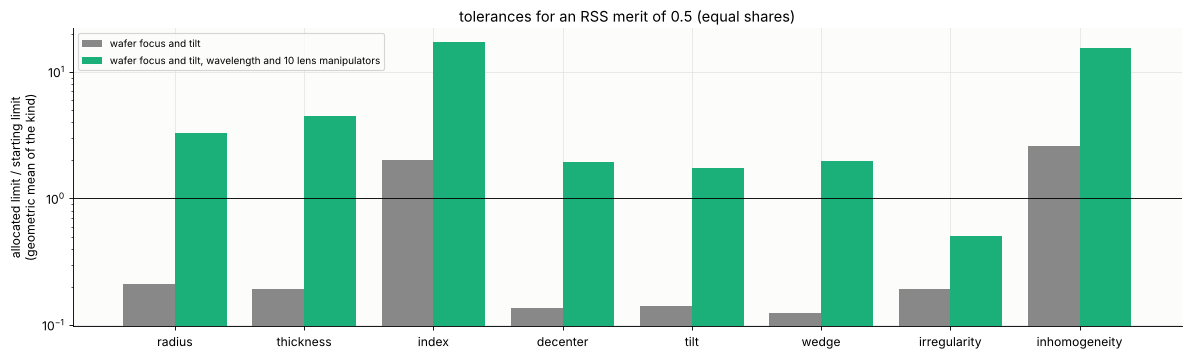

In [10]:
TARGET = 0.5   # RSS merit in specification units
focus_only = stages["+ wafer tilt"]
inv = focus_only.inverse_sensitivity(TARGET)
order = np.argsort(inv/np.array([t.limit for t in tols]))[:12]
print(f"Inverse sensitivity (wafer focus and tilt adjusted): the error at which one tolerance alone takes "
      f"the RSS merit to {TARGET}")
for k in order:
    print(f"  {tols[k].name:14s} {tols[k].group:14s} limit {tols[k].limit:9.3g}   inverse sensitivity {inv[k]:9.3g}")

alloc = {}
for label in ("+ wafer tilt", f"+ {N_MAN} lens manipulators"):
    m = stages[label]
    lim = m.allocate(TARGET)
    lim = np.minimum(lim, 20*np.array([t.limit for t in tols]))   # no more than 20 times the start
    alloc[label] = (lim, m.with_limits(lim))
fig, ax = plt.subplots(figsize=(15, 4.6))
for k, (label, (lim, m)) in enumerate(alloc.items()):
    ratio = lim/np.array([t.limit for t in tols])
    med = [np.exp(np.mean(np.log(ratio[[t.group == g for t in tols]]))) for g in groups]
    ax.bar(np.arange(len(groups)) + (k - 0.5)*0.4, med, 0.4, color=(GREY, GREEN)[k],
           label=("wafer focus and tilt", f"wafer focus and tilt, wavelength and {N_MAN} lens manipulators")[k])
ax.axhline(1, color="k", lw=0.8)
ax.set_yscale("log")
ax.set_xticks(range(len(groups)), groups)
ax.set_ylabel("allocated limit / starting limit\n(geometric mean of the kind)")
ax.set_title(f"tolerances for an RSS merit of {TARGET} (equal shares)")
ax.legend(fontsize=9)
fig.tight_layout()

- The inverse sensitivities say that one tilt or wedge of 0.6 µrad, one
  air space error of 0.2 µm or one decentre of 0.2 µm alone, with the wafer
  focus and tilt adjusted, already uses up the budget: far below what can be
  made.
- Allocated with only the wafer focus and tilt, every geometric tolerance has
  to be about **five to eight times tighter** than the precision set: about
  0.15 µm of centring and 0.7 µrad of tilt. Index and inhomogeneity could be
  two to three times looser.
- Allocated with the manipulators, decentres, tilts and wedges become about
  **twice as loose** as the precision set, radii and thicknesses three to
  five times, the glass more than ten times: about **fifteen times looser**
  than without manipulators. Only the irregularity has to be tighter than in
  the precision set (about half): figure errors make high-order aberrations
  that no rigid body motion of an element can produce.

This is why a scanner lens has manipulators at all. The lens is not made to
the tolerances it needs: it is made to tolerances that can be built, then
measured interferometrically and set up with its manipulators, and the
manipulators keep it there while it heats up in operation.

Both allocations give the same merit, and both pass the specification for
nearly all lenses (Monte Carlo of the linear model):

In [11]:
for label, (lim, m) in alloc.items():
    w = budget.wafer_errors(errors, m.monte_carlo(N_MC, seed=2, vectors=True).vectors)
    show_summary(w, f"allocated tolerances, compensators up to '{label.strip('+ ')}'")

allocated tolerances, compensators up to 'wafer tilt':
  dense V 250/500   CD 3σ   1.2 nm   placement 3σ   3.7 nm   best focus 3σ    18 nm, range across the slit    12 nm
  dense H 250/500   CD 3σ   0.3 nm   placement 3σ   6.3 nm   best focus 3σ    24 nm, range across the slit    11 nm
  iso V 250/1500    CD 3σ   3.8 nm   placement 3σ   4.4 nm   best focus 3σ    19 nm, range across the slit    12 nm
  yield (|ΔCD| ≤ 5 nm, |Δ placement| ≤ 10 nm, |Δ best focus| ≤ 50 nm everywhere): 98.8 %


allocated tolerances, compensators up to '10 lens manipulators':
  dense V 250/500   CD 3σ   1.4 nm   placement 3σ   3.1 nm   best focus 3σ    20 nm, range across the slit    14 nm
  dense H 250/500   CD 3σ   0.3 nm   placement 3σ   5.2 nm   best focus 3σ    26 nm, range across the slit    14 nm
  iso V 250/1500    CD 3σ   3.2 nm   placement 3σ   3.0 nm   best focus 3σ    19 nm, range across the slit    16 nm
  yield (|ΔCD| ≤ 5 nm, |Δ placement| ≤ 10 nm, |Δ best focus| ≤ 50 nm everywhere): 99.8 %


### Manipulator strokes

The price of the loose tolerances is stroke: the manipulators have to move
further. The ranges are soft (a penalty, not a limit), and with the
allocated tolerances the 3σ strokes exceed them up to about three times,
while the wavelength, whose range of 2 pm is small against what it would
need to do, hardly moves at all. A real design loop goes on from here:
larger strokes where they are cheap, hard limits, more manipulators, or
tighter tolerances for the errors that drive the largest strokes (the matrix
`LinearModel.D` gives the compensator motion per error).

wafer focus    3σ stroke    11.7 µm
wafer tilt y   3σ stroke    26.1 µrad
wavelength     3σ stroke     0.2 pm
x E4           3σ stroke    89.6 µm
z E10          3σ stroke   140.0 µm
tilt y E13     3σ stroke   133.7 µrad
z E6           3σ stroke    40.1 µm
y E16          3σ stroke    32.8 µm
x E3           3σ stroke    52.1 µm
z E17          3σ stroke    85.1 µm
z E13          3σ stroke    88.0 µm
tilt x E13     3σ stroke    79.6 µrad
z E7           3σ stroke    58.9 µm
total run time 643 s


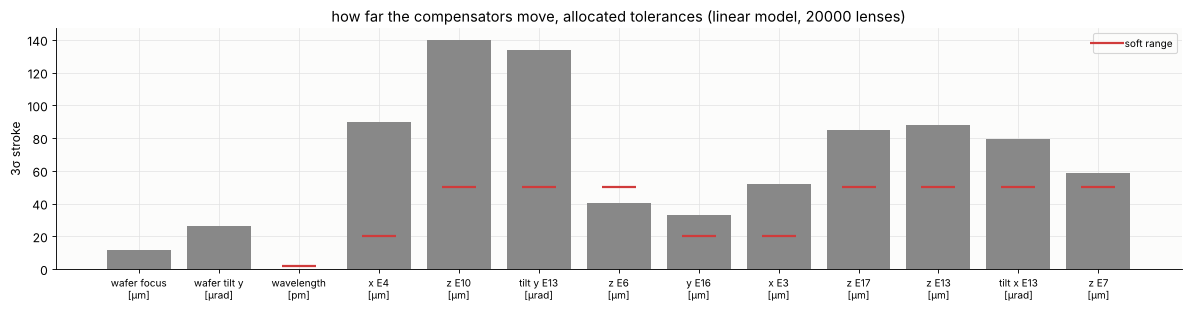

In [12]:
strokes = alloc[f"+ {N_MAN} lens manipulators"][1].monte_carlo(N_MC, seed=1).compensators
UNIT = {lo.Thickness: (1e3, "µm"), tol.ImageTilt: (1e6, "µrad"), tol.Wavelength: (1e9, "pm"),
        lo.AirSpace: (1e3, "µm"), tol.LateralShift: (1e3, "µm"), tol.ElementTilt: (1e6, "µrad")}
fig, ax = plt.subplots(figsize=(15, 4))
for k, c in enumerate(comps):
    f, u = UNIT[type(c)]
    ax.bar(k, 3*np.std(strokes[:, k])*f, color=GREY)
    if RANGE.get(type(c)) is not None:
        ax.plot(k, RANGE[type(c)]*f, "_", color=RED, ms=30, mew=2, label="soft range" if k == 2 else None)
    print(f"{mlabel(c):14s} 3σ stroke {3*np.std(strokes[:, k])*f:7.1f} {u}")
ax.set_xticks(range(len(comps)), [f"{mlabel(c)}\n[{UNIT[type(c)][1]}]" for c in comps], fontsize=9)
ax.set_ylabel("3σ stroke")
ax.set_title("how far the compensators move, allocated tolerances (linear model, 20000 lenses)")
ax.legend(fontsize=9)
fig.tight_layout()
print(f"total run time {time.time() - t_start:.0f} s")

## Summary

- `pyoptics.tolerancing` now has element **tilt** (rigid body about a pivot),
  **wedge**, surface **irregularity** in fringes of a Zernike shape and
  index **inhomogeneity** of the blank, the compensators `ElementTilt`,
  `ImageTilt` and `Wavelength`, soft **ranges** of the compensators (damped
  least squares), Monte Carlo runs that keep the **performance vectors**, and
  **inverse sensitivity** and **allocation** of tolerances from a budget
  (`LinearModel.inverse_sensitivity()`, `allocate()`, `with_limits()`).
- `pyoptics.litho.budget` chains a perturbed lens to the wafer: Zernikes and
  placements across the slit (`SlitAberrations`, with the scanner's linear
  correction), the sensitivities of each feature about the nominal lens at
  each slit position (`slit_sensitivities()`), the lithographic error vector
  that the compensators minimize (`LithoErrors`), and CD, placement and best
  focus changes, their statistics and the yield (`wafer_errors()`,
  `wafer_summary()`, `wafer_yield()`).
- For Caldwell's KrF lens, a precision tolerance set (1 µm centring, 5 µrad
  tilts, 2 µm thicknesses, 0.05 fringe irregularity) is limited by the tilts,
  wedges and decentres. With only the wafer focus adjusted no lens meets a
  5 nm CD, 10 nm placement and 50 nm best focus budget; wafer levelling,
  the wavelength and ten manipulators bring two thirds of the lenses into
  specification, and with the manipulators the tolerances that meet the
  budget are about fifteen times looser than without them; only the
  surface irregularity cannot be relaxed.
- The linear model agrees with full traces to a fraction of a nanometre,
  for the tolerances alone and with thirteen compensators.

Exercises: average over the scan (`SlitAberrations(..., y=np.linspace(-2.5, 2.5, 3))`)
and see the tilts about $x$ appear; add contact holes or a dipole source
(the sensitivities change completely); weight the allocation by cost
(`weights=`, e.g. loose irregularity, tight centring); hold the irregularity
fixed at what the polishing shop can deliver (`fixed=`) and allocate the
rest; replace the wavelength by an extra axial manipulator; do the same for
the ArF immersion lens `zeiss_arfi_lens()` of
notebook 33 (lens aberrations across the slit).

## References

- T. Matsuyama, Y. Ohmura and D. M. Williamson, "The lithographic lens: its history and evolution", Proc. SPIE 6154, 615403 (2006).
- A. Erdmann, *Optical and EUV Lithography: A Modeling Perspective*, SPIE Press (2021).
- C. Mack, *Fundamental Principles of Optical Lithography: The Science of Microfabrication*, Wiley (2007).
- J. B. Caldwell, "All-fused-silica 248-nm lithographic projection lens", Optics & Photonics News 9(11), 40-41 (1998).
- W. J. Smith, *Modern Optical Engineering*, 4th ed., McGraw-Hill (2008) (tolerances, inverse sensitivity and allocation).
- K. P. Thompson, "Description of the third-order optical aberrations of near-circular pupil optical systems without symmetry", J. Opt. Soc. Am. A 22, 1389-1401 (2005) (aberrations of tilted and decentred elements).